# Oxfordshire house prices dashboard

In [3]:
import sys
print(sys.executable)
print(sys.prefix)

c:\Users\Tom\Exercism\python\Week_12_dashboards\.venv\Scripts\python.exe
c:\Users\Tom\Exercism\python\Week_12_dashboards\.venv


In [4]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt



In [7]:
loaded = pd.read_parquet('data/pp_epc_oxfordshire_2015_2025_v2.parquet')

print(loaded.shape)
print(loaded.dtypes)

(114424, 44)
unique_id                                 str
price_paid                              int64
deed_date                      datetime64[ns]
address                                   str
saon                                      str
paon                                      str
street                                    str
locality                                  str
town                                      str
district                                  str
postcode                                  str
property_subtype                          str
new_build                                 str
estate_type                               str
transaction_category                      str
certificate_number                        str
built_form                                str
construction_age_band                     str
current_energy_efficiency               int64
current_energy_rating                     str
energy_consumption_current            float64
extension_count      

### Questions
- For a property investor
    - How does £ per sqm floor_area vary between districts? Where is space cheapest?
    - Do homes with poor energy efficiency sell at a discount (per m2)?
        - Landlords have to meet a minimum energy rating to let, which may be raised
    - Do prices or sales volume vary throughout the year? When are they lowest/highest?
        - Compare months within a year to avoid long term price rise trend
    - Do new builds cost more per m2?
    - What has been the overall price/volume trend since 2015?
        - Did sales volumes or prices change when tax changes took place?
            - Extra stamp duty changes (first in April 2016 for additional properties then increased)

In [ ]:
loaded['transaction_category'].value_counts()

transaction_category
A    105046
B      9378
Name: count, dtype: int64

year
2015    0.047802
2016    0.063367
2017    0.079416
2018    0.089947
2019    0.099197
2020    0.078537
2021    0.079758
2022    0.081721
2023    0.101753
2024    0.100585
2025    0.081928
Name: share_b, dtype: float64


<Axes: xlabel='year', ylabel='share_b'>

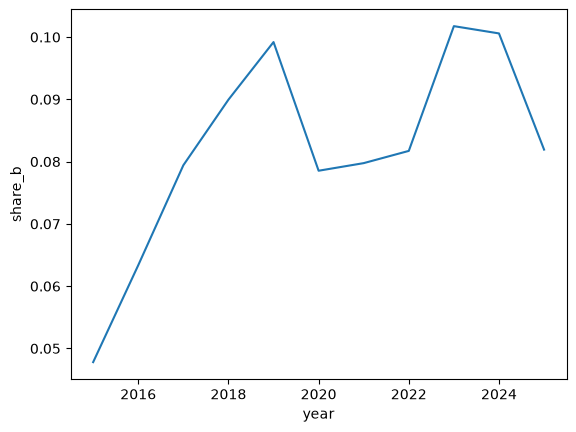

In [29]:
loaded['share_b'] = (loaded['transaction_category'] == 'B')
share_b_table = loaded.groupby('year')['share_b'].mean()
print(share_b_table)
sns.lineplot(share_b_table)


In [27]:
pd.crosstab(loaded['year'], loaded['transaction_category'], normalize='index')

transaction_category,A,B
year,,
2015,0.952198,0.047802
2016,0.936633,0.063367
2017,0.920584,0.079416
2018,0.910053,0.089947
2019,0.900803,0.099197
2020,0.921463,0.078537
2021,0.920242,0.079758
2022,0.918279,0.081721
2023,0.898247,0.101753


     year  month  unique_id
120  2025      1        765
121  2025      2        819
122  2025      3       1617
123  2025      4        357
124  2025      5        649
125  2025      6        926
126  2025      7        863
127  2025      8        953
128  2025      9        856
129  2025     10        872
130  2025     11        727
131  2025     12        678


<Axes: xlabel='month', ylabel='unique_id'>

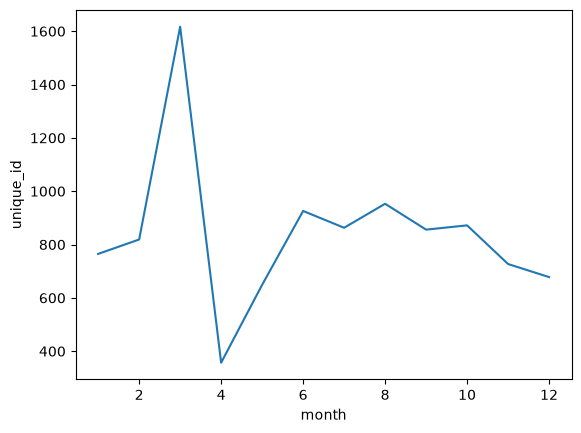

In [68]:
monthly_vol = pd.DataFrame(loaded.groupby(['year', 'month'])['unique_id'].count()).reset_index()
print(monthly_vol[monthly_vol['year'] == 2025])
sns.lineplot(monthly_vol[monthly_vol['year'] == 2025], x = 'month', y='unique_id')

# Faceting exercise

In [114]:
cat_a_only = loaded[loaded['transaction_category'] == 'A'].copy()
cat_a_only.shape

(105046, 45)

<Axes: xlabel='£/m2', ylabel='property_subtype'>

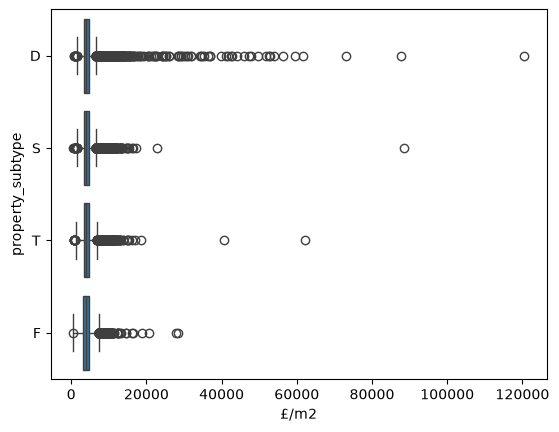

In [115]:
cat_a_only['£/m2'] = cat_a_only['price_paid'] / cat_a_only['total_floor_area']
sns.boxplot(cat_a_only, x='£/m2', y='property_subtype')


- O (Other) property_subtype no present in the data

In [116]:
recent_years = cat_a_only[cat_a_only['year'].isin([2023, 2024, 2025])]
recent_years.groupby(['property_subtype', 'district'])['unique_id'].count()

property_subtype  district           
D                 CHERWELL               1939
                  OXFORD                  339
                  SOUTH OXFORDSHIRE      2142
                  VALE OF WHITE HORSE    2419
                  WEST OXFORDSHIRE       1348
F                 CHERWELL                619
                  OXFORD                  795
                  SOUTH OXFORDSHIRE       732
                  VALE OF WHITE HORSE     769
                  WEST OXFORDSHIRE        553
S                 CHERWELL               1929
                  OXFORD                 1096
                  SOUTH OXFORDSHIRE      1951
                  VALE OF WHITE HORSE    1873
                  WEST OXFORDSHIRE       1229
T                 CHERWELL               1618
                  OXFORD                 1167
                  SOUTH OXFORDSHIRE      1309
                  VALE OF WHITE HORSE    1260
                  WEST OXFORDSHIRE       1027
Name: unique_id, dtype: int64

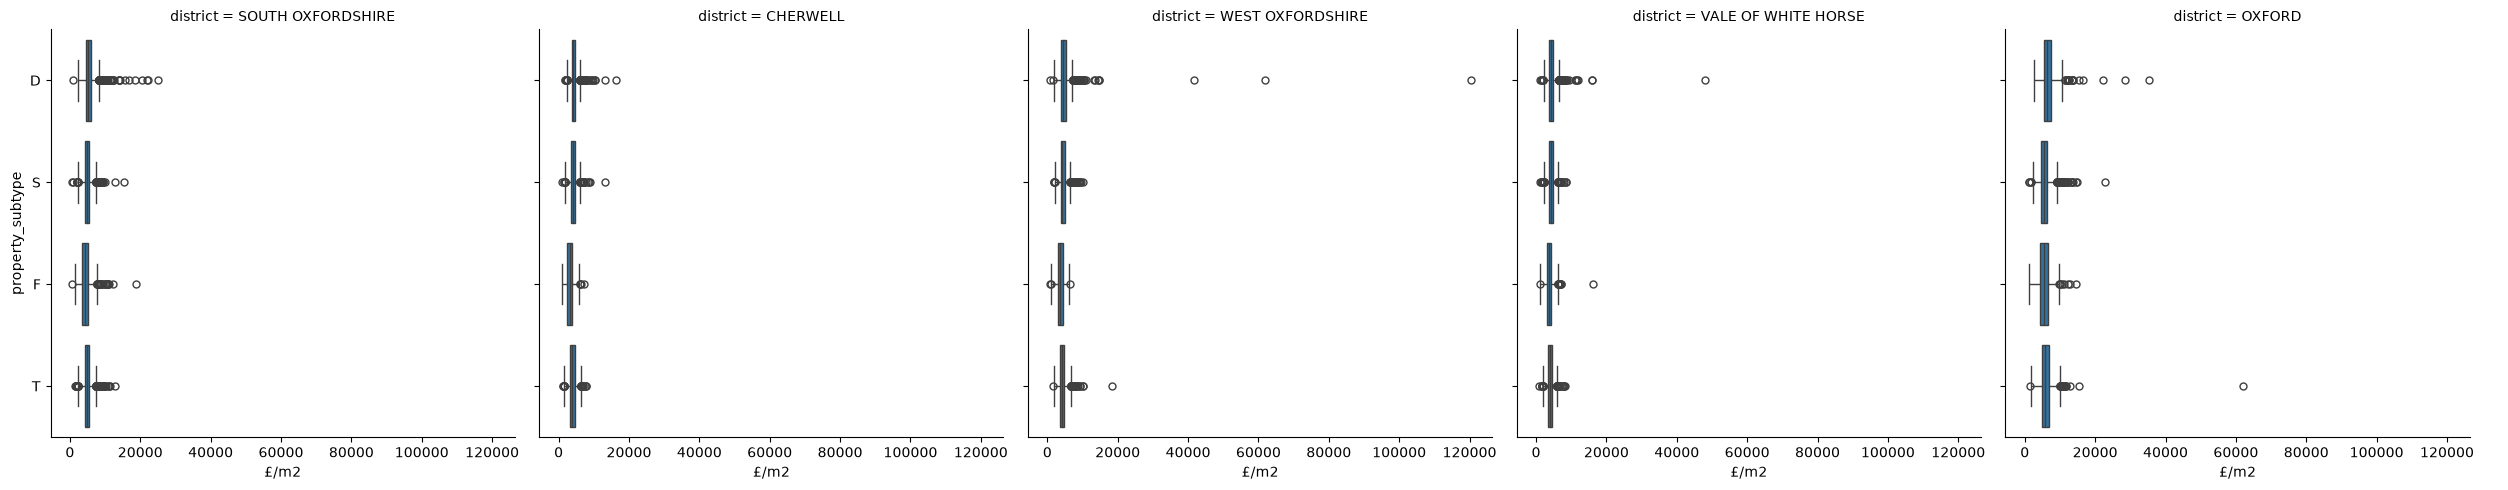

In [117]:
g = sns.catplot(recent_years, x= '£/m2', y='property_subtype', col='district', kind='box')
# g.set(xlim=(0, 40000))

In [118]:
cat_a_only[cat_a_only['£/m2'] > 25000][['unique_id', 'address', 'price_paid', 'total_floor_area', 'number_habitable_rooms', 'property_subtype', '£/m2']].sort_values(by='£/m2', ascending=False)

,unique_id,address,price_paid,total_floor_area,number_habitable_rooms,property_subtype,£/m2
104391,38EDC0C3-3B52-0F63-E063-4704A8C00424,NEW GARDENS COTTAGE LEDWELL ROAD GREAT TEW OX7...,16500000,137.0,5.0,D,120437.956204
80842,F87E72F9-526D-176C-E053-6B04A8C0D2BE,10 STRATFIELD ROAD OX2 7BQ,1595000,18.0,1.0,S,88611.111111
112426,EA3278AA-5AAE-2676-E053-6B04A8C015F8,YEW TREE HOUSE LONGWORTH OX13 5EP,3250000,37.0,1.0,D,87837.837838
107269,EA3278AA-5D10-2676-E053-6B04A8C015F8,JORDLEYS MANOR ROAD GORING RG8 9EN,1900000,26.0,1.0,D,73076.923077
92194,2F7F2B43-5A4B-E08F-E063-4804A8C05A49,10 KINGSTON ROAD OX2 6EF,1055000,17.0,1.0,T,62058.823529
42452,42C129E4-F972-60A9-E063-4804A8C0C25D,LINCOLN FARMHOUSE HIGH STREET STANDLAKE OX29 7RH,1420000,23.0,2.0,D,61739.130435
95033,726BF13B-27FD-0A46-E053-6C04A8C01D0D,YEW TREE HOUSE LONGWORTH OX13 5EP,2200000,37.0,1.0,D,59459.459459
42755,A96E4ACC-724F-9205-E053-6C04A8C0DA09,COTTONSTONES MILL ROAD SHIPLAKE RG9 3LT,2425000,43.0,1.0,D,56395.348837
73817,B0A9D11B-B3FD-4C1F-E053-6C04A8C0D716,THE MILL COTTAGE LOCK APPROACH GORING RG8 9AD,3878250,72.0,1.0,D,53864.583333
97373,C74B2393-1C6C-4751-89F0-F519A836CACB,ORCHARD LEA PLAYHATCH RG4 9QU,1325000,25.0,1.0,D,53000.000000


(105046, 47)
(104942, 47)


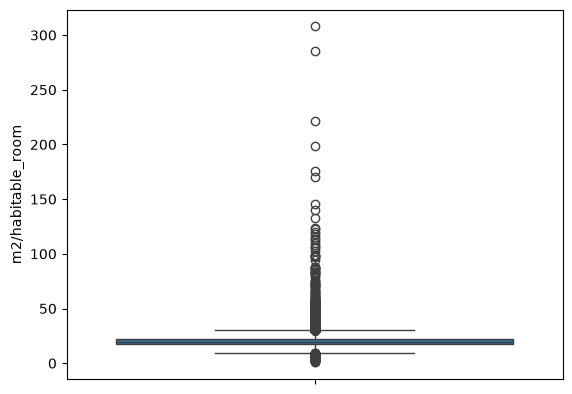

In [ ]:
cat_a_only['m2/habitable_room'] = cat_a_only['total_floor_area'] / cat_a_only['number_habitable_rooms']
print(cat_a_only.shape)
sns.boxplot(cat_a_only['m2/habitable_room'])


In [126]:
# cat_a_only[~((cat_a_only['m2/habitable_room'] >= 10) & (cat_a_only['m2/habitable_room'] < 200))].dropna(subset= 'm2/habitable_room')
cat_a_only[((cat_a_only['m2/habitable_room'] >= 9))].dropna(subset= 'm2/habitable_room').sort_values('m2/habitable_room')

,unique_id,price_paid,deed_date,address,saon,paon,street,locality,town,district,...,EPC_expired,dayofweek,day,month,quarter,year,floor_height_imputed,share_b,£/m2,m2/habitable_room
37213,4E95D757-BB30-EDA1-E050-A8C0630539E2,145000,2016-09-21,8 NEITHROP CLOSE OX16 2NU,NaN,8,NEITHROP CLOSE,NaN,BANBURY,CHERWELL,...,False,2,21,9,3,2016,False,False,4027.777778,9.000000
78128,31FB4C17-CFA8-57B9-E050-A8C063053436,263000,2016-03-31,105 GREEN RIDGES HEADINGTON OX3 8LX,NaN,105,GREEN RIDGES,HEADINGTON,OXFORD,OXFORD,...,False,3,31,3,1,2016,False,False,9740.740741,9.000000
21618,BEF7EBBF-3479-7A76-E053-6B04A8C092F7,450000,2021-02-08,ALETA OLD LONDON ROAD MILTON COMMON OX9 2JR,NaN,ALETA,OLD LONDON ROAD,MILTON COMMON,THAME,SOUTH OXFORDSHIRE,...,False,0,8,2,1,2021,False,False,10000.000000,9.000000
49131,3B5CE842-1929-EE3A-E063-4804A8C0D6F1,285000,2024-08-15,40 MEADOW VIEW OX16 9SS,NaN,40,MEADOW VIEW,NaN,BANBURY,CHERWELL,...,False,3,15,8,3,2024,False,False,3904.109589,9.125000
27875,31FB4C17-CF4C-57B9-E050-A8C063053436,425000,2016-03-24,17 TITUP HALL DRIVE HEADINGTON OX3 8QQ,NaN,17,TITUP HALL DRIVE,HEADINGTON,OXFORD,OXFORD,...,False,3,24,3,1,2016,False,False,6640.625000,9.142857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54095,98C75472-38E4-72E9-E053-6B04A8C042F0,1300000,2019-11-04,18 JACK STRAWS LANE HEADINGTON OX3 0DL,NaN,18,JACK STRAWS LANE,HEADINGTON,OXFORD,OXFORD,...,False,0,4,11,4,2019,False,False,7386.363636,176.000000
30790,559C5AD5-70BC-AFE3-E063-4804A8C004A4,1200000,2025-12-09,THE CROFT RADLEY ROAD OX14 3PP,NaN,THE CROFT,RADLEY ROAD,NaN,ABINGDON,VALE OF WHITE HORSE,...,False,1,9,12,4,2025,False,False,6030.150754,199.000000
36708,4777E0AF-104F-5D59-E063-4804A8C09F8E,1050000,2025-07-04,EASTBROOK SOUTH STREET BLEWBURY OX11 9PR,NaN,EASTBROOK,SOUTH STREET,BLEWBURY,DIDCOT,VALE OF WHITE HORSE,...,False,4,4,7,3,2025,False,False,4751.131222,221.000000
57625,34222872-A9DD-4D2B-E063-4704A8C07853,2150000,2024-08-12,FOUR SYCAMORES MILL ROAD SHIPLAKE RG9 3LW,NaN,FOUR SYCAMORES,MILL ROAD,SHIPLAKE,HENLEY-ON-THAMES,SOUTH OXFORDSHIRE,...,False,0,12,8,3,2024,False,False,7543.859649,285.000000


In [ ]:

cat_a_only_room_filt = cat_a_only[((cat_a_only['m2/habitable_room'] >= 10) & (cat_a_only['m2/habitable_room'] < 200)) | (cat_a_only['number_habitable_rooms'].isna())]
print(cat_a_only_room_filt.shape)